# 4 · Refining the graph

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/04_refining_the_graph.ipynb)

Tutorial 3 showed that a graph with far fewer edges can classify almost as
well. Choosing a builder is one way to get there. **Graph refinement** is
another: it takes a graph that is already built and removes rare words and
weak edges before training, without rebuilding anything.

We first **measure** what each refinement removes, which takes seconds and
needs no training. Then we **train** on a few of the refined graphs.

> **Runtime:** about 30 min on CPU. Building the TF-IDF graph takes about 5 min
> on any hardware, because it runs on the CPU; a GPU speeds up only the training.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | Your first classifier | How do I go from raw text to test accuracy? |
| 3 | Choosing a graph builder | How should words be connected? |
| 4 | **Refining the graph** | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

In [2]:
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

from text4gcn import GNN, Builder, RefinementConfig, TextPipeline, apply_refinement
from text4gcn.builder import Frequency
from text4gcn.datasets import twenty_newsgroups
from text4gcn.models.utils import LoadData

In [3]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

In [4]:
shutil.rmtree(DATA_DIR, ignore_errors=True)   # start clean: outputs of older runs would be reused
twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)
TextPipeline(dataset_name=NAME, dataset_path=DATA_DIR, seed=SEED).execute(validation_ratio=0.10)
Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)

[2026/10/16 17:39:56] [INFO] ======================================== NLTK Configuration ========================================


[nltk_data] Downloading package stopwords to /home/vitor/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/vitor/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/vitor/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


[2026/10/16 17:39:56] [INFO] Random seed (shuffle) = <1234>
[2026/10/16 17:39:56] [INFO] Validation ratio = <0.1>
[2026/10/16 17:39:56] [INFO] 
[2026/10/16 17:39:56] [INFO] ============================= CLEANED DATA: Removed rare & stop-words. =============================
[2026/10/16 17:39:56] [INFO] Start process: 1792168796.3668742


[2026/10/16 17:39:57] [INFO] Rare-Count = <5>
[2026/10/16 17:39:57] [INFO] Elapsed time is 1.112285 seconds.
[2026/10/16 17:39:57] [INFO] 
[2026/10/16 17:39:57] [INFO] ============================ SHUFFLED DATA: Corpus documents shuffled. =============================
[2026/10/16 17:39:57] [INFO] Start process: 1792168797.4793324


[2026/10/16 17:39:57] [INFO] Elapsed time is 0.240038 seconds.
[2026/10/16 17:39:57] [INFO] 
[2026/10/16 17:39:57] [INFO] ======================= PREPARED WORDS: Vocabulary & word-vectors extracted. =======================
[2026/10/16 17:39:57] [INFO] Start process: 1792168797.719639


...

[2026/10/16 17:40:09] [INFO] Calculating PMI


[2026/10/16 17:44:55] [INFO] Calculating TF-IDF


[2026/10/16 17:44:59] [INFO] [INFO] (4534779, (4534779, 4534779)), shape=(14537, 14537)


[2026/10/16 17:45:02] [INFO] GraphBuildStats(frequency.tfidf: nodes=14537, edges(nnz)=4534779, density=2.145886e-02, file=51.95 MiB)
[2026/10/16 17:45:03] [INFO] Elapsed time is 295.422656 seconds.
[2026/10/16 17:45:03] [INFO] 
[2026/10/16 17:45:03] [WARN] Directory:'data/log' already exists, not overwritten.


GraphBuildStats(n_nodes=14537, n_edges=4534779, density=0.02145885503625945, file_bytes=54475923, builder='frequency.tfidf', dataset_name='20NG4', path='data/20NG4.adjacency/ind.frequency.tfidf.20NG4.adj')

## The knobs

`RefinementConfig` combines node filters and edge pruning. Document nodes are
always kept (`keep_docs=True`), so the train, validation and test sets do not
change.

| Option | Removes |
|---|---|
| `min_doc_freq=k` | words that occur in fewer than $k$ documents |
| `max_doc_freq_ratio=r` | words that occur in more than a fraction $r$ of the documents |
| `edge_weight_threshold=w` | edges with a PMI or TF-IDF weight below $w$ |
| `top_k_edges_per_node=k` | all but the $k$ heaviest edges of each node |

See the [refinement guide](https://vitormeriat.github.io/text4gcn/guides/refinement/) for the full list.

## Measure before you train

`LoadData(...).load_corpus()` loads the graph and features that `GNN` would
train on. `apply_refinement(..., return_metadata=True)` returns the refined
graph together with statistics, without training.

In [5]:
predata = LoadData(path=DATA_DIR, dataset=NAME, builder=Builder.Tfidf).load_corpus()
weights = predata[0].tocsr().data          # PMI and TF-IDF weights of every edge

quantiles = pd.Series(np.quantile(weights, [0.1, 0.25, 0.5, 0.75, 0.9]),
                      index=["10%", "25%", "50%", "75%", "90%"])
print(f"{len(weights):,} edges; weight quantiles:")
quantiles.round(2)


Show info about load data:

Data      Shape
--------  --------------
x         (1973, 300)
y         (1973, 4)
tx        (1455, 300)
ty        (1455, 4)
allx      (13082, 300)
ally      (13082, 4)
adj       (14537, 14537)
Features  (14537, 300)
Labels    (14537, 4)


4,811,118 edges; weight quantiles:


10%    0.45
25%    1.02
50%    2.05
75%    3.39
90%    4.80
dtype: float64

Most weights are well above 1, so a threshold like `0.05` would remove
almost nothing. **Pick thresholds from the distribution of your own graph.**
Here we use the median (removes half of the edges) and the 90th percentile
(removes 90%).

In [6]:
median, p90 = quantiles["50%"], quantiles["90%"]
candidates = {
    "original": RefinementConfig(),
    "min_doc_freq=3": RefinementConfig(min_doc_freq=3),
    "min_doc_freq=10": RefinementConfig(min_doc_freq=10),
    f"weight ≥ {median:.2f} (median)": RefinementConfig(edge_weight_threshold=median),
    f"weight ≥ {p90:.2f} (p90)": RefinementConfig(edge_weight_threshold=p90),
    "top-20 edges/node": RefinementConfig(top_k_edges_per_node=20),
}

sizes = pd.DataFrame({
    name: apply_refinement(predata, config, dataset_path=DATA_DIR, dataset_name=NAME,
                           return_metadata=True)[1]["stats"]
    for name, config in candidates.items()
}).T
sizes["edges kept"] = sizes.edges_after / sizes.loc["original", "edges_after"]
sizes[["nodes_refined", "edges_after", "edges kept"]].style.format(
    {"nodes_refined": "{:,}", "edges_after": "{:,}", "edges kept": "{:.0%}"})

,nodes_refined,edges_after,edges kept
original,"14,537","4,811,118",100%
min_doc_freq=3,"13,923","4,694,726",98%
min_doc_freq=10,"8,743","3,201,726",67%
weight ≥ 2.05 (median),"14,537","2,405,562",50%
weight ≥ 4.80 (p90),"14,537","481,112",10%
top-20 edges/node,"14,537","403,284",8%


The filters act differently:

* `min_doc_freq` removes **word nodes**: rare words and all their edges.
* Weight thresholds and `top_k_edges_per_node` keep every node and remove
  **edges**. `top-k` is the most aggressive: hub words lose most of their links.

## Does accuracy survive?

We train on the original graph and on three refined ones. `GNN` applies the
refinement after loading the graph and prints the same statistics as above.

In [7]:
to_train = ["original", "min_doc_freq=3", f"weight ≥ {median:.2f} (median)", "top-20 edges/node"]

accuracy = {}
for name in to_train:
    result = GNN(dataset_name=NAME, dataset_path=DATA_DIR, log_dir=LOG_DIR, builder=Builder.Tfidf,
                 seed=SEED, refinement_config=candidates[name]).fit()
    accuracy[name] = result.test_accuracy

summary = sizes.loc[to_train, ["nodes_refined", "edges kept"]].assign(test_accuracy=pd.Series(accuracy))
summary.style.format({"nodes_refined": "{:,}", "edges kept": "{:.0%}", "test_accuracy": "{:.2%}"})

Using device: cpu

============================== MODEL CONFIGURATION
Namespace(early_stopping=10, seed=1234, val_ratio=0.1, max_epoch=200, dataset='20NG4', dropout=0.5, log_dir=PosixPath('logs'), layer=<Layer.GCN: 'GCN'>, nhid=200, lr=0.02, device=device(type='cpu'))




Show info about load data:

Data      Shape
--------  --------------
x         (1973, 300)
y         (1973, 4)
tx        (1455, 300)
ty        (1455, 4)
allx      (13082, 300)
ally      (13082, 4)
adj       (14537, 14537)
Features  (14537, 300)
Labels    (14537, 4)



Graph refinement stats: {'nodes_original': 14537, 'nodes_refined': 14537, 'nodes_removed': 0, 'edges_before': 4811118, 'edges_after': 4811118, 'train_docs_kept': 1973, 'test_docs_kept': 1455}



Data statistics

  Edges    Classes    Train samples    Val samples    Test samples
-------  ---------  ---------------  -------------  --------------
  14537          4             1973            219            1455



Model structure:

 GCN(
  (layer1): GraphConvolution(
    (act_func): ReLU()
    (dropout): Dropout(p=0.5, inplace=False)
  )
  (layer2): GraphConvolution(
    (dropout): Dropout(p=0.5, inplace=False)
  )
) 

Dropout rate: 0.5
Layer: layer1.W0 | Size: torch.Size([14537, 200])
Layer: layer2.W0 | Size: torch.Size([200, 4])

∎∎∎∎∎∎∎∎∎∎∎∎∎∎∎∎∎∎∎∎ Torch Seed: 1234


...

Epoch:0080, train_loss=1.19942, train_acc=0.99949, val_loss=1.36846, val_acc=0.92237, time=8.16945


Epoch:0081, train_loss=1.19940, train_acc=0.99949, val_loss=1.36846, val_acc=0.92237, time=7.22637
Early stopping at epoch 81. Restoring best validation checkpoint (val_loss=1.36845).

Completed 81 epochs — train_loss=1.1994, best_val_loss=1.3685, last_train_acc=0.9995



Optimization Finished!



Test set results: loss=1.29894, accuracy=0.83024, time=0.80762

Test Precision, Recall and F1-Score...
              precision    recall  f1-score   support

           0     0.7535    0.8516    0.7995       384
           1     0.9016    0.8707    0.8859       379
           2     0.7645    0.6408    0.6972       309
           3     0.8914    0.9217    0.9063       383

    accuracy                         0.8302      1455
   macro avg     0.8277    0.8212    0.8222      1455
weighted avg     0.8307    0.8302    0.8284      1455


Macro average Test Precision, Recall and F1-Score...
(0.8277471178383394, 0.8211806545903244, 0.822222564209432, None)

Micro average Test Precision, Recall and F1-Score...
(0.8302405498281787, 0.8302405498281787, 0.8302405498281787, None)

Weighted average Test Precision, Recall and F1-Score...
(0.8307106905849185, 0.8302405498281787, 0.8283912755425747, None)

Confusion Matrix...
[[327  12  34  11]
 [ 19 330  13  17]
 [ 83  13 198  15]
 [  5  11  14 353]

,nodes_refined,edges kept,test_accuracy
original,"14,537",100%,86.74%
min_doc_freq=3,"13,923",98%,86.94%
weight ≥ 2.05 (median),"14,537",50%,86.53%
top-20 edges/node,"14,537",8%,83.02%


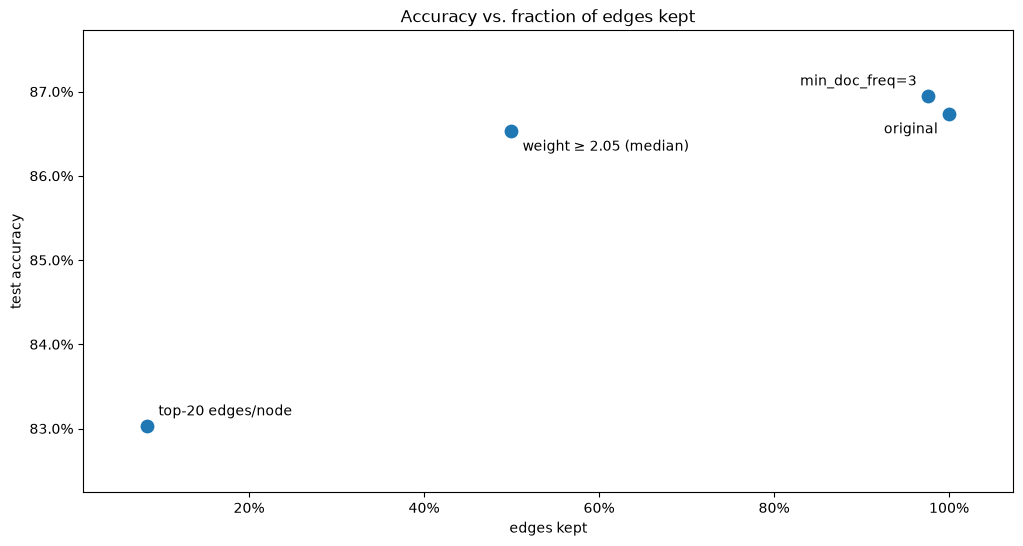

In [8]:
ax = summary.plot.scatter(x="edges kept", y="test_accuracy", s=80, figsize=(12, 6),
                          title="Accuracy vs. fraction of edges kept")
for k, (name, row) in enumerate(summary.iterrows()):
    right_side = row["edges kept"] > 0.9            # label to the left of points near 100%
    ax.annotate(name, (row["edges kept"], row.test_accuracy), textcoords="offset points",
                xytext=(-8 if right_side else 8, 8 if k % 2 else -14),
                ha="right" if right_side else "left")
ax.set_ylabel("test accuracy")
ax.margins(x=0.08, y=0.2)
ax.xaxis.set_major_formatter("{x:.0%}")
ax.yaxis.set_major_formatter("{x:.1%}");

## What the numbers say

On our CPU run (seed 1234):

* `min_doc_freq=3` removed about 600 rare words and **lost nothing** (86.9% vs
  86.7%). Fewer nodes means less memory, because the dense GCN grows with the
  square of the node count.
* Dropping the weaker half of the edges (keeping $w \geq$ median) cost only about
  **0.2 points** (86.5%). Moderate pruning is safe.
* `top-20 edges/node` kept only **8%** of the edges, but accuracy dropped by
  about **3.7 points** (83.0%).
* Compare that with tutorial 3: the **Word2Vec RWF** graph kept about 6% of the
  edges and lost only about **1 point**.

The difference is *which* edges go. `top-k` treats all edges alike, so documents
with more than 20 words lose document–word edges: only 45% of them survive. The
RWF removes word–word edges only and keeps every document–word edge, and
tutorial 3 showed that on this corpus those edges carry most of the signal.

## Takeaways

* **Measure first.** Graph statistics take seconds; training takes minutes.
* **Prune words, not just edges.** `min_doc_freq` is a safe first step.
* For an order-of-magnitude smaller graph, **change the builder** (tutorial 3)
  rather than pruning TF-IDF + PMI.
* **Keep the document–word edges.** Filters that remove them, like `top-k`, cost
  the most accuracy.
* Refinement works with any builder: pass `refinement_config` together with `builder`.

**Next:** so far we have used a benchmark. [5 · Bring your own corpus](https://vitormeriat.github.io/text4gcn/tutorials/05_bring_your_own_corpus/)
shows how to prepare your own data, in any language.